In [6]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_FOLDER = Path(
    r"C:\Users\hp\OneDrive\Desktop\ml lab8\team8\data\ExtractedData"
)

team_number = 8
class_labels = np.array([3, 6, 7])
n_classes = len(class_labels)

In [7]:
sequences = []
labels = []
recording_ids = []

for digit in class_labels:
    file_path = DATA_FOLDER / f"{digit}.npz"

    if not file_path.is_file():
        raise FileNotFoundError(
            f"File not found: {file_path}"
        )

    with np.load(file_path, allow_pickle=False) as archive:
        # Numeric ordering: arr_0, arr_1, ..., arr_449.
        keys = sorted(
            archive.files,
            key=lambda name: int(name.rsplit("_", 1)[1])
        )

        for key in keys:
            sequence = np.asarray(
                archive[key],
                dtype=float
            )

            if sequence.ndim != 2:
                raise ValueError(
                    f"Digit {digit}, {key}: expected a 2D array."
                )

            if sequence.shape[0] == 0:
                raise ValueError(
                    f"Digit {digit}, {key}: empty recording."
                )

            if sequence.shape[1] != 39:
                raise ValueError(
                    f"Digit {digit}, {key}: expected 39 features, "
                    f"found {sequence.shape[1]}."
                )

            if not np.isfinite(sequence).all():
                raise ValueError(
                    f"Digit {digit}, {key}: contains "
                    "missing or infinite values."
                )

            sequences.append(sequence.copy())
            labels.append(int(digit))
            recording_ids.append(f"{digit}/{key}")

labels = np.asarray(labels, dtype=int)
recording_ids = np.asarray(recording_ids)

n_features = sequences[0].shape[1]

# Summarize recording lengths separately for each digit.
dataset_rows = []

for digit in class_labels:
    indices = np.flatnonzero(labels == digit)

    lengths = np.array([
        len(sequences[index])
        for index in indices
    ])

    dataset_rows.append({
        "Digit": digit,
        "Recordings": len(indices),
        "Features per frame": n_features,
        "Minimum frames": lengths.min(),
        "Maximum frames": lengths.max(),
        "Mean frames": lengths.mean()
    })

dataset_summary = pd.DataFrame(dataset_rows)

print("Dataset loaded successfully.")
print("Total recordings:", len(sequences))
print("Class labels:", class_labels)
print("Features per frame:", n_features)

print("\nDataset summary:")
print(
    dataset_summary.round(2).to_string(index=False)
)

print("\nFirst recording ID:", recording_ids[0])
print("First recording shape:", sequences[0].shape)
print("\nFirst three frames:")
print(sequences[0][:3])

Dataset loaded successfully.
Total recordings: 1350
Class labels: [3 6 7]
Features per frame: 39

Dataset summary:
 Digit  Recordings  Features per frame  Minimum frames  Maximum frames  Mean frames
     3         450                  39              63             184        97.10
     6         450                  39              84             171       115.53
     7         450                  39              71             161       103.55

First recording ID: 3/arr_0
First recording shape: (81, 39)

First three frames:
[[-0.85803735 -0.40217057  0.46869317 -0.52421856 -0.46675569  0.21200818
  -0.46732998  0.83093065  0.08192983  0.53303963  0.26750103 -0.42286935
   0.44535625  0.50580478  0.2341772  -0.44402698 -0.71582782 -0.7937181
  -0.20370124 -0.16860625  0.05863538  0.65723431  0.32859474 -0.29726213
  -0.74377435 -1.6952076  -1.07832646 -0.66846734  0.42495197  0.61525881
   0.47238755  0.45473254 -0.05256717  0.16850913 -0.33284223  0.78556532
  -0.20038903 -1.0175236

In [8]:
train_indices = []
val_indices = []
test_indices = []

for digit in class_labels:
    digit_indices = np.flatnonzero(labels == digit)
    positions = np.arange(len(digit_indices))

    val_indices.extend(
        digit_indices[positions % 5 == 0]
    )

    test_indices.extend(
        digit_indices[positions % 5 == 1]
    )

    train_indices.extend(
        digit_indices[positions % 5 >= 2]
    )

train_indices = np.sort(
    np.asarray(train_indices, dtype=int)
)

val_indices = np.sort(
    np.asarray(val_indices, dtype=int)
)

test_indices = np.sort(
    np.asarray(test_indices, dtype=int)
)

# Verify that recording indices do not overlap.
assert np.intersect1d(
    train_indices, val_indices
).size == 0

assert np.intersect1d(
    train_indices, test_indices
).size == 0

assert np.intersect1d(
    val_indices, test_indices
).size == 0

assert (
    len(train_indices)
    + len(val_indices)
    + len(test_indices)
    == len(sequences)
)

# Lists preserve variable-length sequences.
train_sequences = [
    sequences[index] for index in train_indices
]

val_sequences = [
    sequences[index] for index in val_indices
]

test_sequences = [
    sequences[index] for index in test_indices
]

y_train = labels[train_indices]
y_val = labels[val_indices]
y_test = labels[test_indices]

train_ids = recording_ids[train_indices]
val_ids = recording_ids[val_indices]
test_ids = recording_ids[test_indices]

split_rows = []

for name, split_sequences, split_labels in [
    ("Training", train_sequences, y_train),
    ("Validation", val_sequences, y_val),
    ("Testing", test_sequences, y_test)
]:
    row = {
        "Split": name,
        "Recordings": len(split_labels),
        "Total frames": sum(
            len(sequence) for sequence in split_sequences
        )
    }

    for digit in class_labels:
        row[f"Digit {digit}"] = int(
            np.sum(split_labels == digit)
        )

    split_rows.append(row)

split_summary = pd.DataFrame(split_rows)

print(split_summary.to_string(index=False))

     Split  Recordings  Total frames  Digit 3  Digit 6  Digit 7
  Training         810         85307      270      270      270
Validation         270         28448       90       90       90
   Testing         270         28526       90       90       90


In [9]:
# Temporarily combine TRAINING frames to estimate statistics.
# These rows are frames, not independent recording samples.
training_frames = np.vstack(train_sequences)

frame_mean = training_frames.mean(axis=0)
frame_std = training_frames.std(axis=0)

frame_std_safe = np.where(
    frame_std == 0,
    1.0,
    frame_std
)


def scale_sequences(sequence_list, mean, std):
    return [
        (sequence - mean) / std
        for sequence in sequence_list
    ]


train_sequences_scaled = scale_sequences(
    train_sequences,
    frame_mean,
    frame_std_safe
)

val_sequences_scaled = scale_sequences(
    val_sequences,
    frame_mean,
    frame_std_safe
)

test_sequences_scaled = scale_sequences(
    test_sequences,
    frame_mean,
    frame_std_safe
)

scaled_training_frames = np.vstack(
    train_sequences_scaled
)

# Name the 39 frame-level features.
feature_names = (
    [f"MFCC_{i}" for i in range(13)]
    + [f"Delta_{i}" for i in range(13)]
    + [f"DeltaDelta_{i}" for i in range(13)]
)

scaling_summary = pd.DataFrame({
    "Feature": feature_names,
    "Training mean after scaling": (
        scaled_training_frames.mean(axis=0)
    ),
    "Training std after scaling": (
        scaled_training_frames.std(axis=0)
    )
})

print(
    scaling_summary.round(6).to_string(index=False)
)

print("\nExample recording shapes after scaling:")

for digit in class_labels:
    index = np.flatnonzero(y_train == digit)[0]

    print(
        f"Digit {digit}: "
        f"{train_sequences_scaled[index].shape}"
    )

      Feature  Training mean after scaling  Training std after scaling
       MFCC_0                         -0.0                         1.0
       MFCC_1                          0.0                         1.0
       MFCC_2                         -0.0                         1.0
       MFCC_3                          0.0                         1.0
       MFCC_4                          0.0                         1.0
       MFCC_5                         -0.0                         1.0
       MFCC_6                          0.0                         1.0
       MFCC_7                         -0.0                         1.0
       MFCC_8                         -0.0                         1.0
       MFCC_9                          0.0                         1.0
      MFCC_10                          0.0                         1.0
      MFCC_11                         -0.0                         1.0
      MFCC_12                         -0.0                         1.0
      

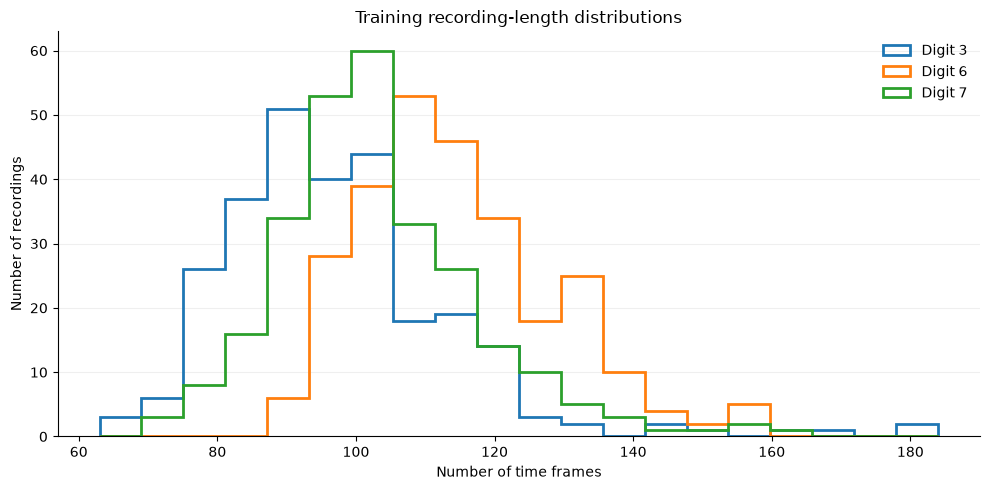

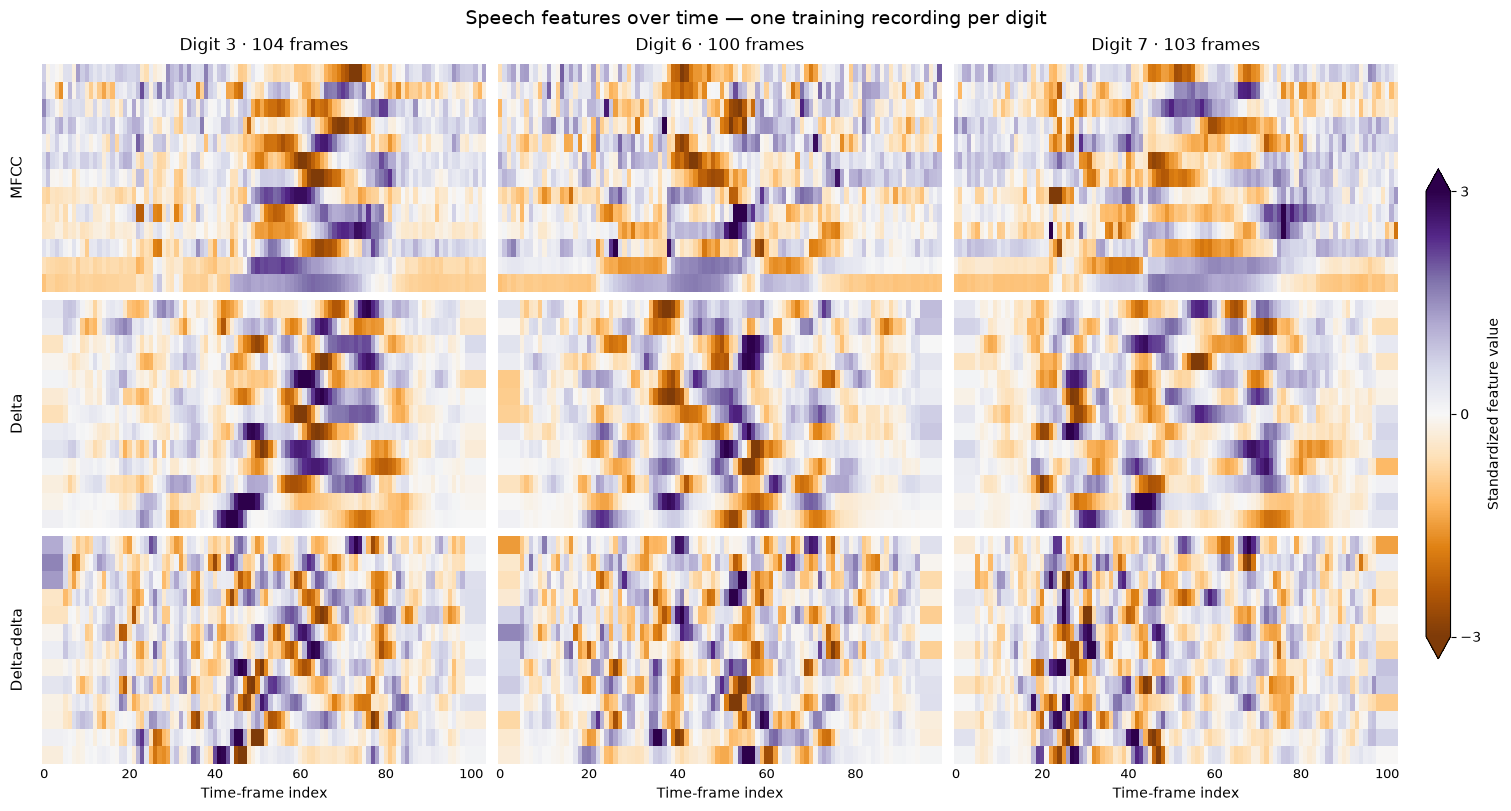

In [10]:
class_colors = {
    digit: plt.get_cmap("tab10")(index)
    for index, digit in enumerate(class_labels)
}

# --------------------------------------------------
# A. Training recording-length distributions
# --------------------------------------------------
# Common bin edges allow direct comparison between classes.
training_lengths = np.array([
    len(sequence) for sequence in train_sequences
])

bin_edges = np.linspace(
    training_lengths.min(),
    training_lengths.max(),
    21
)

fig, ax = plt.subplots(figsize=(10, 5))

for digit in class_labels:
    indices = np.flatnonzero(y_train == digit)

    lengths = [
        len(train_sequences[index])
        for index in indices
    ]

    ax.hist(
        lengths,
        bins=bin_edges,
        histtype="step",
        linewidth=2,
        color=class_colors[digit],
        label=f"Digit {digit}"
    )

ax.set_xlabel("Number of time frames")
ax.set_ylabel("Number of recordings")
ax.set_title("Training recording-length distributions")
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

# --------------------------------------------------
# B. Speech-feature heatmaps
# One column per digit; one row per feature group.
# --------------------------------------------------
feature_groups = [
    ("MFCC", 0, 13),
    ("Delta", 13, 26),
    ("Delta-delta", 26, 39)
]

fig, axes = plt.subplots(
    3,
    n_classes,
    figsize=(15, 8),
    sharex="col",
    constrained_layout=True,
    squeeze=False
)

for column, digit in enumerate(class_labels):
    index = np.flatnonzero(y_train == digit)[0]
    sequence = train_sequences_scaled[index]

    for row, (group_name, start, end) in enumerate(
        feature_groups
    ):
        ax = axes[row, column]

        image = ax.imshow(
            sequence[:, start:end].T,
            origin="lower",
            aspect="auto",
            cmap="PuOr",
            vmin=-3,
            vmax=3,
            interpolation="nearest"
        )

        ax.set_yticks([])

        ax.tick_params(
            axis="both",
            labelsize=9,
            length=0
        )

        for spine in ax.spines.values():
            spine.set_visible(False)

        if column == 0:
            ax.set_ylabel(
                group_name,
                fontsize=11,
                labelpad=12
            )

        if row == 0:
            ax.set_title(
                f"Digit {digit} · {len(sequence)} frames",
                fontsize=12,
                pad=10
            )

        if row == 2:
            ax.set_xlabel(
                "Time-frame index",
                fontsize=10
            )

fig.suptitle(
    "Speech features over time — one training recording per digit",
    fontsize=14
)

colorbar = fig.colorbar(
    image,
    ax=axes.ravel().tolist(),
    shrink=0.7,
    pad=0.02,
    extend="both"
)

colorbar.set_label("Standardized feature value")
colorbar.set_ticks([-3, 0, 3])

plt.show()

In [11]:
def temporal_pool_sequences(sequence_list, n_segments=5):
    """Represent each recording using consecutive segment means."""
    feature_vectors = []

    for sequence in sequence_list:
        if len(sequence) < n_segments:
            raise ValueError(
                "Recording has fewer frames than segments."
            )

        segments = np.array_split(
            sequence,
            n_segments,
            axis=0
        )

        feature_vector = np.concatenate([
            segment.mean(axis=0)
            for segment in segments
        ])

        feature_vectors.append(feature_vector)

    return np.vstack(feature_vectors)


# Fixed beforehand; not chosen using test results.
n_segments = 5

X_train = temporal_pool_sequences(
    train_sequences_scaled,
    n_segments
)

X_val = temporal_pool_sequences(
    val_sequences_scaled,
    n_segments
)

X_test = temporal_pool_sequences(
    test_sequences_scaled,
    n_segments
)

# Scale recording-level features using training statistics only.
pooled_mean = X_train.mean(axis=0)
pooled_std = X_train.std(axis=0)

pooled_std_safe = np.where(
    pooled_std == 0,
    1.0,
    pooled_std
)

X_train_scaled = (X_train - pooled_mean) / pooled_std_safe
X_val_scaled = (X_val - pooled_mean) / pooled_std_safe
X_test_scaled = (X_test - pooled_mean) / pooled_std_safe

n_recording_features = X_train.shape[1]

print("Fixed-length recording representations:")
print("Training:", X_train_scaled.shape)
print("Validation:", X_val_scaled.shape)
print("Testing:", X_test_scaled.shape)

print("\nFrame features:", n_features)
print("Temporal segments:", n_segments)
print("Features per recording:", n_recording_features)

Fixed-length recording representations:
Training: (810, 195)
Validation: (270, 195)
Testing: (270, 195)

Frame features: 39
Temporal segments: 5
Features per recording: 195


In [12]:
def accuracy_score_manual(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    if y_true.shape != y_pred.shape:
        raise ValueError(
            "Actual and predicted label shapes differ."
        )

    return np.mean(y_true == y_pred)


def confusion_matrix_manual(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    if y_true.shape != y_pred.shape:
        raise ValueError(
            "Actual and predicted label shapes differ."
        )

    label_to_index = {
        label: index
        for index, label in enumerate(class_labels)
    }

    matrix = np.zeros(
        (len(class_labels), len(class_labels)),
        dtype=int
    )

    for actual, predicted in zip(y_true, y_pred):
        if actual not in label_to_index:
            raise ValueError(f"Unknown actual label: {actual}")

        if predicted not in label_to_index:
            raise ValueError(
                f"Unknown predicted label: {predicted}"
            )

        matrix[
            label_to_index[actual],
            label_to_index[predicted]
        ] += 1

    return matrix


def show_evaluation(
    name,
    y_true,
    y_pred,
    split_name="Validation"
):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    accuracy = accuracy_score_manual(y_true, y_pred)
    matrix = confusion_matrix_manual(y_true, y_pred)

    correct = int(np.sum(y_true == y_pred))

    print(
        f"{name} — {split_name} accuracy: "
        f"{100 * accuracy:.3f}%"
    )

    print("Correct predictions:", correct)
    print("Incorrect predictions:", len(y_true) - correct)

    print("\nConfusion matrix:")
    print(pd.DataFrame(
        matrix,
        index=[
            f"Actual {label}" for label in class_labels
        ],
        columns=[
            f"Predicted {label}" for label in class_labels
        ]
    ))

    return accuracy

In [13]:
#LDA
class ManualLDA:
    def __init__(self, regularization=1e-4):
        self.regularization = regularization

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y)

        self.classes_ = np.unique(y)

        n_samples, feature_count = X.shape
        class_count = len(self.classes_)

        if n_samples <= class_count:
            raise ValueError(
                "Need more samples than classes."
            )

        self.means_ = np.zeros(
            (class_count, feature_count)
        )

        self.priors_ = np.zeros(class_count)

        pooled_scatter = np.zeros(
            (feature_count, feature_count)
        )

        for index, class_label in enumerate(self.classes_):
            class_data = X[y == class_label]

            self.means_[index] = class_data.mean(axis=0)
            self.priors_[index] = len(class_data) / n_samples

            centered = class_data - self.means_[index]
            pooled_scatter += centered.T @ centered

        self.covariance_ = (
            pooled_scatter / (n_samples - class_count)
        )

        self.covariance_ += (
            self.regularization * np.eye(feature_count)
        )

        self.weights_ = np.linalg.solve(
            self.covariance_,
            self.means_.T
        )

        self.intercepts_ = (
            -0.5 * np.sum(
                self.means_.T * self.weights_,
                axis=0
            )
            + np.log(self.priors_)
        )

        return self

    def decision_function(self, X):
        X = np.asarray(X, dtype=float)

        return X @ self.weights_ + self.intercepts_

    def predict(self, X):
        scores = self.decision_function(X)

        return self.classes_[
            np.argmax(scores, axis=1)
        ]


# Train using recording-level training features.
lda_model = ManualLDA(regularization=1e-4)
lda_model.fit(X_train_scaled, y_train)

lda_val_predictions = lda_model.predict(
    X_val_scaled
)

lda_val_accuracy = show_evaluation(
    "LDA — temporal features",
    y_val,
    lda_val_predictions
)

LDA — temporal features — Validation accuracy: 98.148%
Correct predictions: 265
Incorrect predictions: 5

Confusion matrix:
          Predicted 3  Predicted 6  Predicted 7
Actual 3           88            0            2
Actual 6            0           89            1
Actual 7            2            0           88


In [14]:
#KNN
class ManualKNN:
    def __init__(self, batch_size=128):
        self.batch_size = batch_size

    def fit(self, X, y):
        self.X_train_ = np.asarray(X, dtype=float)
        self.y_train_ = np.asarray(y)

        self.classes_, self.encoded_y_ = np.unique(
            self.y_train_,
            return_inverse=True
        )

        self.train_squared_norms_ = np.sum(
            self.X_train_ ** 2,
            axis=1
        )

        return self

    def predict_for_k_values(self, X, k_values):
        X = np.asarray(X, dtype=float)

        if X.shape[1] != self.X_train_.shape[1]:
            raise ValueError(
                "Training and prediction feature counts differ."
            )

        k_values = sorted(set(k_values))

        if not k_values or any(
            not isinstance(k, (int, np.integer))
            or k < 1
            or k > len(self.X_train_)
            for k in k_values
        ):
            raise ValueError(
                "Each k must be a valid positive integer."
            )

        max_k = max(k_values)

        predictions = {
            k: np.empty(
                len(X),
                dtype=self.classes_.dtype
            )
            for k in k_values
        }

        for start in range(0, len(X), self.batch_size):
            end = min(start + self.batch_size, len(X))
            batch = X[start:end]

            # Squared Euclidean distances.
            distances = (
                np.sum(batch ** 2, axis=1)[:, None]
                + self.train_squared_norms_[None, :]
                - 2 * batch @ self.X_train_.T
            )

            distances = np.maximum(distances, 0.0)

            nearest_indices = np.argsort(
                distances,
                axis=1,
                kind="stable"
            )[:, :max_k]

            nearest_labels = self.encoded_y_[
                nearest_indices
            ]

            for k in k_values:
                votes = np.column_stack([
                    np.sum(
                        nearest_labels[:, :k] == class_index,
                        axis=1
                    )
                    for class_index in range(len(self.classes_))
                ])

                # Smallest class label wins a voting tie.
                predicted_indices = np.argmax(
                    votes,
                    axis=1
                )

                predictions[k][start:end] = (
                    self.classes_[predicted_indices]
                )

        return predictions

In [15]:
knn_model = ManualKNN(batch_size=128)
knn_model.fit(X_train_scaled, y_train)

neighbor_values = [1, 3, 5, 7, 11]

knn_val_predictions = knn_model.predict_for_k_values(
    X_val_scaled,
    neighbor_values
)

knn_rows = []

for k in neighbor_values:
    predictions = knn_val_predictions[k]

    correct = int(np.sum(predictions == y_val))
    errors = len(y_val) - correct

    accuracy = accuracy_score_manual(
        y_val,
        predictions
    )

    knn_rows.append({
        "Neighbours": k,
        "Correct": correct,
        "Errors": errors,
        "Validation accuracy (%)": 100 * accuracy
    })

knn_validation_table = pd.DataFrame(knn_rows)

print("KNN validation comparison:")
print(
    knn_validation_table.round(3).to_string(index=False)
)

# Highest accuracy first; smaller k wins a tie.
ranked_candidates = knn_validation_table.sort_values(
    by=["Validation accuracy (%)", "Neighbours"],
    ascending=[False, True]
)

best_k = int(
    ranked_candidates.iloc[0]["Neighbours"]
)

print(f"\nSelected number of neighbours: {best_k}\n")

best_knn_val_accuracy = show_evaluation(
    f"KNN — temporal features (k={best_k})",
    y_val,
    knn_val_predictions[best_k]
)

validation_results = [
    {
        "Classifier": "LDA",
        "Representation": "5-segment means",
        "Setting": "Shared covariance",
        "Validation accuracy (%)": 100 * lda_val_accuracy
    },
    {
        "Classifier": "KNN",
        "Representation": "5-segment means",
        "Setting": f"k={best_k}",
        "Validation accuracy (%)": (
            100 * best_knn_val_accuracy
        )
    }
]

validation_comparison = pd.DataFrame(
    validation_results
)

print("\nClassifier comparison so far:")
print(
    validation_comparison.round(3).to_string(index=False)
)

KNN validation comparison:
 Neighbours  Correct  Errors  Validation accuracy (%)
          1      266       4                   98.519
          3      268       2                   99.259
          5      268       2                   99.259
          7      268       2                   99.259
         11      268       2                   99.259

Selected number of neighbours: 3

KNN — temporal features (k=3) — Validation accuracy: 99.259%
Correct predictions: 268
Incorrect predictions: 2

Confusion matrix:
          Predicted 3  Predicted 6  Predicted 7
Actual 3           90            0            0
Actual 6            0           90            0
Actual 7            2            0           88

Classifier comparison so far:
Classifier  Representation           Setting  Validation accuracy (%)
       LDA 5-segment means Shared covariance                   98.148
       KNN 5-segment means               k=3                   99.259


In [16]:
#GMM
def logsumexp_manual(values, axis=1):
    """Stable calculation of log(sum(exp(values)))."""
    maximum = np.max(
        values,
        axis=axis,
        keepdims=True
    )

    result = maximum + np.log(
        np.sum(
            np.exp(values - maximum),
            axis=axis,
            keepdims=True
        )
    )

    return np.squeeze(result, axis=axis)


def log_diagonal_gaussian(X, mean, variances):
    """Return one Gaussian log density per frame."""
    feature_count = X.shape[1]

    squared_distance = np.sum(
        ((X - mean) ** 2) / variances,
        axis=1
    )

    log_determinant = np.sum(np.log(variances))

    return -0.5 * (
        feature_count * np.log(2 * np.pi)
        + log_determinant
        + squared_distance
    )

In [17]:
class ManualDiagonalGMM:
    def __init__(
        self,
        n_components=1,
        max_iter=200,
        tol=1e-4,
        variance_floor=1e-4
    ):
        self.n_components = n_components
        self.max_iter = max_iter
        self.tol = tol
        self.variance_floor = variance_floor

    def _initialize(self, X):
        sample_count, feature_count = X.shape

        if not 1 <= self.n_components <= sample_count:
            raise ValueError(
                "Invalid number of Gaussian components."
            )

        overall_mean = X.mean(axis=0)

        initial_variances = np.maximum(
            X.var(axis=0),
            self.variance_floor
        )

        if self.n_components == 1:
            self.means_ = overall_mean[None, :].copy()

        else:
            # First mean: frame closest to the overall mean.
            distances = np.sum(
                (X - overall_mean) ** 2,
                axis=1
            )

            first_index = int(np.argmin(distances))
            chosen_indices = [first_index]

            nearest_distance = np.sum(
                (X - X[first_index]) ** 2,
                axis=1
            )

            # Remaining means: farthest from existing means.
            while len(chosen_indices) < self.n_components:
                nearest_distance[chosen_indices] = -np.inf

                next_index = int(
                    np.argmax(nearest_distance)
                )

                if nearest_distance[next_index] <= 0:
                    raise ValueError(
                        "Not enough distinct frames."
                    )

                chosen_indices.append(next_index)

                new_distance = np.sum(
                    (X - X[next_index]) ** 2,
                    axis=1
                )

                nearest_distance = np.minimum(
                    nearest_distance,
                    new_distance
                )

            self.means_ = X[chosen_indices].copy()

        self.variances_ = np.repeat(
            initial_variances[None, :],
            self.n_components,
            axis=0
        )

        self.weights_ = np.full(
            self.n_components,
            1.0 / self.n_components
        )

    def _weighted_log_probabilities(self, X):
        return np.column_stack([
            np.log(self.weights_[component])
            + log_diagonal_gaussian(
                X,
                self.means_[component],
                self.variances_[component]
            )
            for component in range(self.n_components)
        ])

    def fit(self, X):
        X = np.asarray(X, dtype=float)

        if X.ndim != 2 or not np.isfinite(X).all():
            raise ValueError(
                "Expected a finite two-dimensional frame array."
            )

        sample_count = len(X)

        self._initialize(X)

        self.log_likelihood_history_ = []
        self.converged_ = False
        previous_likelihood = None

        for iteration in range(self.max_iter + 1):
            weighted_log_probabilities = (
                self._weighted_log_probabilities(X)
            )

            sample_log_probabilities = logsumexp_manual(
                weighted_log_probabilities,
                axis=1
            )

            average_likelihood = float(
                sample_log_probabilities.mean()
            )

            if not np.isfinite(average_likelihood):
                raise ValueError(
                    "Non-finite GMM log likelihood."
                )

            self.log_likelihood_history_.append(
                average_likelihood
            )

            if previous_likelihood is not None:
                change = abs(
                    average_likelihood - previous_likelihood
                )

                if change < self.tol:
                    self.converged_ = True
                    break

            if iteration == self.max_iter:
                break

            # E-step.
            responsibilities = np.exp(
                weighted_log_probabilities
                - sample_log_probabilities[:, None]
            )

            effective_counts = responsibilities.sum(axis=0)

            if np.any(effective_counts < 1e-8):
                raise ValueError(
                    "A component has negligible membership."
                )

            # M-step: component weights and means.
            self.weights_ = (
                effective_counts / sample_count
            )

            self.means_ = (
                responsibilities.T @ X
            ) / effective_counts[:, None]

            # M-step: diagonal variances.
            for component in range(self.n_components):
                centered = X - self.means_[component]

                variances = np.sum(
                    responsibilities[:, component, None]
                    * centered ** 2,
                    axis=0
                ) / effective_counts[component]

                self.variances_[component] = np.maximum(
                    variances,
                    self.variance_floor
                )

            previous_likelihood = average_likelihood

        self.n_iter_ = iteration

        return self

    def score_samples(self, X):
        X = np.asarray(X, dtype=float)

        return logsumexp_manual(
            self._weighted_log_probabilities(X),
            axis=1
        )

In [18]:
class SpeechGMMClassifier:
    def __init__(
        self,
        n_components=1,
        max_iter=200,
        tol=1e-4,
        variance_floor=1e-4
    ):
        self.n_components = n_components
        self.max_iter = max_iter
        self.tol = tol
        self.variance_floor = variance_floor

    def fit(self, sequence_list, y):
        y = np.asarray(y)

        if len(sequence_list) != len(y):
            raise ValueError(
                "Recording and label counts differ."
            )

        self.classes_ = np.unique(y)
        self.models_ = []

        for digit in self.classes_:
            indices = np.flatnonzero(y == digit)

            # Combine only this digit's training frames.
            digit_frames = np.vstack([
                sequence_list[index]
                for index in indices
            ])

            model = ManualDiagonalGMM(
                n_components=self.n_components,
                max_iter=self.max_iter,
                tol=self.tol,
                variance_floor=self.variance_floor
            )

            model.fit(digit_frames)
            self.models_.append(model)

        self.converged_ = all(
            model.converged_
            for model in self.models_
        )

        return self

    def decision_function(self, sequence_list):
        # Equal class priors: training classes are balanced.
        # Mean frame log density gives a length-normalized score.
        return np.asarray([
            [
                model.score_samples(sequence).mean()
                for model in self.models_
            ]
            for sequence in sequence_list
        ])

    def predict(self, sequence_list):
        scores = self.decision_function(sequence_list)

        return self.classes_[
            np.argmax(scores, axis=1)
        ]

In [19]:
component_values = [1, 2, 4, 8]

gmm_models = {}
gmm_val_predictions = {}
gmm_rows = []

for components in component_values:
    print(
        f"Training speech GMM: "
        f"{components} component(s) per digit...",
        flush=True
    )

    classifier = SpeechGMMClassifier(
        n_components=components,
        max_iter=200,
        tol=1e-4,
        variance_floor=1e-4
    )

    try:
        classifier.fit(
            train_sequences_scaled,
            y_train
        )

        predictions = classifier.predict(
            val_sequences_scaled
        )

        accuracy = accuracy_score_manual(
            y_val,
            predictions
        )

        gmm_models[components] = classifier
        gmm_val_predictions[components] = predictions

        row = {
            "Components per digit": components,
            "Validation accuracy (%)": 100 * accuracy,
            "All digits converged": classifier.converged_,
            "Status": (
                "OK"
                if classifier.converged_
                else "Iteration limit"
            )
        }

        for digit, model in zip(
            classifier.classes_,
            classifier.models_
        ):
            row[f"Digit {digit} EM updates"] = (
                model.n_iter_
            )

    except (ValueError, FloatingPointError) as error:
        print(
            f"  Candidate failed: {error}",
            flush=True
        )

        row = {
            "Components per digit": components,
            "Validation accuracy (%)": np.nan,
            "All digits converged": False,
            "Status": str(error)
        }

    gmm_rows.append(row)

gmm_validation_table = pd.DataFrame(gmm_rows)

print("\nSpeech GMM validation comparison:")
print(
    gmm_validation_table.round(3).to_string(index=False)
)

Training speech GMM: 1 component(s) per digit...
Training speech GMM: 2 component(s) per digit...
Training speech GMM: 4 component(s) per digit...
Training speech GMM: 8 component(s) per digit...

Speech GMM validation comparison:
 Components per digit  Validation accuracy (%)  All digits converged Status  Digit 3 EM updates  Digit 6 EM updates  Digit 7 EM updates
                    1                   34.444                  True     OK                   1                   1                   1
                    2                   86.296                  True     OK                  26                  24                  23
                    4                  100.000                  True     OK                  52                  33                  32
                    8                  100.000                  True     OK                  48                  73                  67


Selected components per digit: 4

Speech GMM (4 components per digit) — Validation accuracy: 100.000%
Correct predictions: 270
Incorrect predictions: 0

Confusion matrix:
          Predicted 3  Predicted 6  Predicted 7
Actual 3           90            0            0
Actual 6            0           90            0
Actual 7            0            0           90

Classifier comparison so far:
Classifier      Representation                          Setting  Validation accuracy (%)
       LDA     5-segment means                Shared covariance                   98.148
       KNN     5-segment means                              k=3                   99.259
       GMM Frame distributions Diagonal, 4 components per digit                  100.000


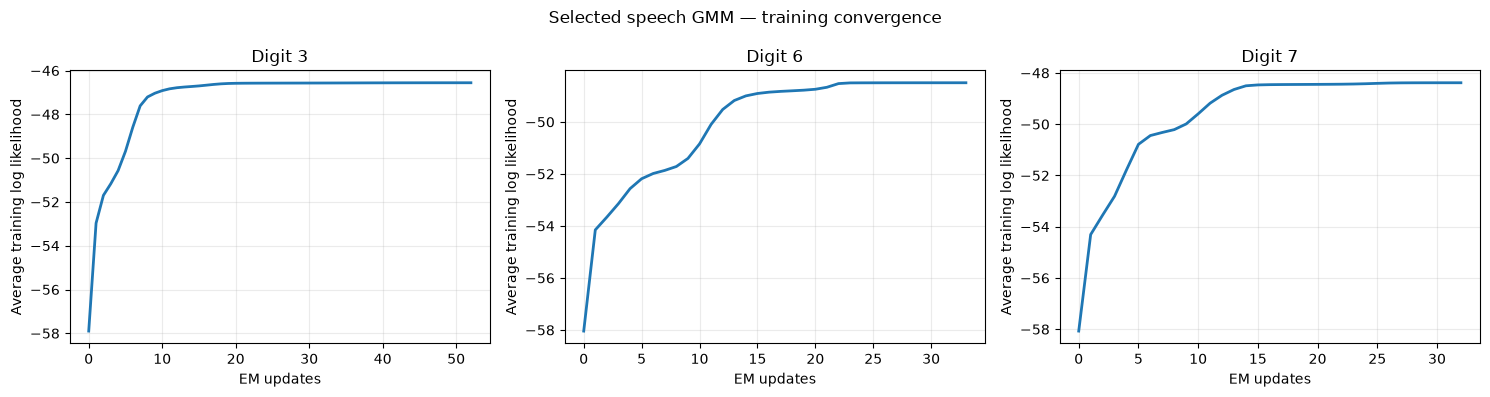

In [20]:
eligible_candidates = gmm_validation_table[
    gmm_validation_table["All digits converged"]
].copy()

if eligible_candidates.empty:
    raise RuntimeError(
        "No GMM candidate fully converged. "
        "Inspect Cell 14 before continuing."
    )

ranked_candidates = eligible_candidates.sort_values(
    by=[
        "Validation accuracy (%)",
        "Components per digit"
    ],
    ascending=[False, True]
)

best_components = int(
    ranked_candidates.iloc[0]["Components per digit"]
)

best_gmm_model = gmm_models[best_components]

print(
    f"Selected components per digit: "
    f"{best_components}\n"
)

best_gmm_val_accuracy = show_evaluation(
    f"Speech GMM ({best_components} components per digit)",
    y_val,
    gmm_val_predictions[best_components]
)

# Compare the completed classifiers.
validation_results = [
    {
        "Classifier": "LDA",
        "Representation": "5-segment means",
        "Setting": "Shared covariance",
        "Validation accuracy (%)": 100 * lda_val_accuracy
    },
    {
        "Classifier": "KNN",
        "Representation": "5-segment means",
        "Setting": f"k={best_k}",
        "Validation accuracy (%)": (
            100 * best_knn_val_accuracy
        )
    },
    {
        "Classifier": "GMM",
        "Representation": "Frame distributions",
        "Setting": (
            f"Diagonal, {best_components} components per digit"
        ),
        "Validation accuracy (%)": (
            100 * best_gmm_val_accuracy
        )
    }
]

validation_comparison = pd.DataFrame(
    validation_results
)

print("\nClassifier comparison so far:")
print(
    validation_comparison.round(3).to_string(index=False)
)

# Plot selected GMM convergence.
fig, axes = plt.subplots(
    1,
    len(class_labels),
    figsize=(15, 4),
    squeeze=False
)

for ax, digit, model in zip(
    axes.flat,
    best_gmm_model.classes_,
    best_gmm_model.models_
):
    history = model.log_likelihood_history_

    ax.plot(
        range(len(history)),
        history,
        linewidth=2
    )

    ax.set_title(f"Digit {digit}")
    ax.set_xlabel("EM updates")
    ax.set_ylabel("Average training log likelihood")
    ax.grid(alpha=0.25)

fig.suptitle("Selected speech GMM — training convergence")

plt.tight_layout()
plt.show()

In [21]:
#SVM
from scipy.optimize import minimize


def svm_objective_and_gradient(parameters, X, y_signed, C):
    weights = parameters[:-1]
    intercept = parameters[-1]

    scores = X @ weights + intercept

    hinge = np.maximum(
        0.0,
        1.0 - y_signed * scores
    )

    # Weight penalty plus mean squared-hinge loss.
    objective = (
        0.5 * np.dot(weights, weights)
        + C * np.mean(hinge ** 2)
    )

    # Derivatives with respect to the decision scores.
    score_gradient = (
        -2.0 * C * y_signed * hinge / len(y_signed)
    )

    weight_gradient = (
        weights + X.T @ score_gradient
    )

    intercept_gradient = np.sum(score_gradient)

    gradient = np.concatenate([
        weight_gradient,
        [intercept_gradient]
    ])

    return objective, gradient

In [22]:
class ManualBinaryLinearSVM:
    def __init__(self, C=1.0, max_iter=3000):
        self.C = C
        self.max_iter = max_iter

    def fit(self, X, y_signed):
        X = np.asarray(X, dtype=float)
        y_signed = np.asarray(y_signed, dtype=float)

        if not np.array_equal(
            np.unique(y_signed),
            np.array([-1.0, 1.0])
        ):
            raise ValueError(
                "Binary SVM requires both -1 and +1 labels."
            )

        # Deterministic initialization.
        initial_parameters = np.zeros(
            X.shape[1] + 1
        )

        self.optimization_result_ = minimize(
            fun=svm_objective_and_gradient,
            x0=initial_parameters,
            args=(X, y_signed, self.C),
            method="L-BFGS-B",
            jac=True,
            options={
                "maxiter": self.max_iter,
                "ftol": 1e-12,
                "gtol": 1e-6
            }
        )

        self.weights_ = (
            self.optimization_result_.x[:-1]
        )

        self.intercept_ = (
            self.optimization_result_.x[-1]
        )

        self.converged_ = bool(
            self.optimization_result_.success
        )

        self.n_iter_ = (
            self.optimization_result_.nit
        )

        return self

    def decision_function(self, X):
        X = np.asarray(X, dtype=float)

        return X @ self.weights_ + self.intercept_


class ManualLinearSVM:
    """Multiclass linear SVM using one-versus-rest."""

    def __init__(self, C=1.0, max_iter=3000):
        self.C = C
        self.max_iter = max_iter

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y)

        self.classes_ = np.unique(y)

        if len(self.classes_) < 2:
            raise ValueError(
                "SVM requires at least two classes."
            )

        self.models_ = []

        for digit in self.classes_:
            binary_labels = np.where(
                y == digit,
                1.0,
                -1.0
            )

            model = ManualBinaryLinearSVM(
                C=self.C,
                max_iter=self.max_iter
            )

            model.fit(X, binary_labels)
            self.models_.append(model)

        self.converged_ = all(
            model.converged_
            for model in self.models_
        )

        return self

    def decision_function(self, X):
        return np.column_stack([
            model.decision_function(X)
            for model in self.models_
        ])

    def predict(self, X):
        scores = self.decision_function(X)

        return self.classes_[
            np.argmax(scores, axis=1)
        ]

In [23]:
C_values = [0.01, 0.1, 1.0, 10.0, 100.0]

svm_models = {}
svm_val_predictions = {}
svm_rows = []

for C in C_values:
    print(
        f"Training multiclass linear SVM with C={C}...",
        flush=True
    )

    model = ManualLinearSVM(
        C=C,
        max_iter=3000
    )

    model.fit(X_train_scaled, y_train)

    predictions = model.predict(
        X_val_scaled
    )

    accuracy = accuracy_score_manual(
        y_val,
        predictions
    )

    correct = int(
        np.sum(predictions == y_val)
    )

    svm_models[C] = model
    svm_val_predictions[C] = predictions

    row = {
        "C": C,
        "Correct": correct,
        "Errors": len(y_val) - correct,
        "Validation accuracy (%)": 100 * accuracy,
        "All digits converged": model.converged_
    }

    for digit, binary_model in zip(
        model.classes_,
        model.models_
    ):
        row[f"Digit {digit} iterations"] = (
            binary_model.n_iter_
        )

        if not binary_model.converged_:
            print(
                f"  Digit {digit}: "
                f"{binary_model.optimization_result_.message}",
                flush=True
            )

    svm_rows.append(row)

svm_validation_table = pd.DataFrame(
    svm_rows
)

print("\nLinear SVM validation comparison:")
print(
    svm_validation_table.round(3).to_string(index=False)
)

Training multiclass linear SVM with C=0.01...
Training multiclass linear SVM with C=0.1...
Training multiclass linear SVM with C=1.0...
Training multiclass linear SVM with C=10.0...
Training multiclass linear SVM with C=100.0...

Linear SVM validation comparison:
     C  Correct  Errors  Validation accuracy (%)  All digits converged  Digit 3 iterations  Digit 6 iterations  Digit 7 iterations
  0.01      259      11                   95.926                  True                  11                  11                  10
  0.10      259      11                   95.926                  True                  13                  13                  13
  1.00      266       4                   98.519                  True                  27                  26                  24
 10.00      265       5                   98.148                  True                  58                  61                  55
100.00      263       7                   97.407                  True           

In [24]:
eligible_candidates = svm_validation_table[
    svm_validation_table["All digits converged"]
].copy()

if eligible_candidates.empty:
    raise RuntimeError(
        "No SVM candidate fully converged. "
        "Inspect the optimizer messages in Cell 18."
    )

ranked_candidates = eligible_candidates.sort_values(
    by=["Validation accuracy (%)", "C"],
    ascending=[False, True]
)

best_C = float(
    ranked_candidates.iloc[0]["C"]
)

best_svm_model = svm_models[best_C]

print(f"Selected C: {best_C}\n")

best_svm_val_accuracy = show_evaluation(
    f"Linear SVM — temporal features (C={best_C})",
    y_val,
    svm_val_predictions[best_C]
)

Selected C: 1.0

Linear SVM — temporal features (C=1.0) — Validation accuracy: 98.519%
Correct predictions: 266
Incorrect predictions: 4

Confusion matrix:
          Predicted 3  Predicted 6  Predicted 7
Actual 3           88            1            1
Actual 6            0           89            1
Actual 7            1            0           89


Speech classification — validation comparison:
Classifier      Representation                          Setting  Validation accuracy (%)
       LDA     5-segment means                Shared covariance                   98.148
       KNN     5-segment means                              k=3                   99.259
       GMM Frame distributions Diagonal, 4 components per digit                  100.000
Linear SVM     5-segment means           One-versus-rest, C=1.0                   98.519


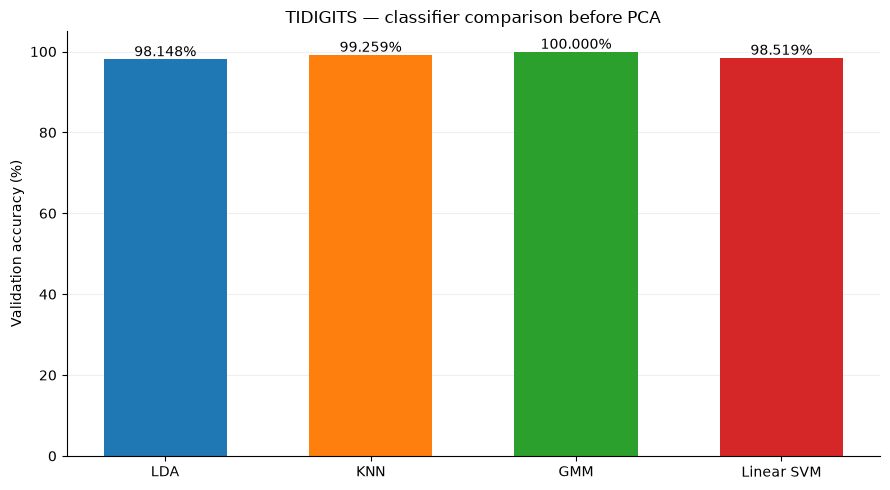

In [25]:
validation_results = [
    {
        "Classifier": "LDA",
        "Representation": "5-segment means",
        "Setting": "Shared covariance",
        "Validation accuracy (%)": (
            100 * lda_val_accuracy
        )
    },
    {
        "Classifier": "KNN",
        "Representation": "5-segment means",
        "Setting": f"k={best_k}",
        "Validation accuracy (%)": (
            100 * best_knn_val_accuracy
        )
    },
    {
        "Classifier": "GMM",
        "Representation": "Frame distributions",
        "Setting": (
            f"Diagonal, {best_components} components per digit"
        ),
        "Validation accuracy (%)": (
            100 * best_gmm_val_accuracy
        )
    },
    {
        "Classifier": "Linear SVM",
        "Representation": "5-segment means",
        "Setting": f"One-versus-rest, C={best_C}",
        "Validation accuracy (%)": (
            100 * best_svm_val_accuracy
        )
    }
]

validation_comparison = pd.DataFrame(
    validation_results
)

print("Speech classification — validation comparison:")
print(
    validation_comparison.round(3).to_string(index=False)
)

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    validation_comparison["Classifier"],
    validation_comparison["Validation accuracy (%)"],
    color=[
        "tab:blue",
        "tab:orange",
        "tab:green",
        "tab:red"
    ],
    width=0.6
)

for bar, accuracy in zip(
    bars,
    validation_comparison["Validation accuracy (%)"]
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        accuracy + 0.7,
        f"{accuracy:.3f}%",
        ha="center"
    )

ax.set_ylim(0, 105)
ax.set_ylabel("Validation accuracy (%)")
ax.set_title("TIDIGITS — classifier comparison before PCA")
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

In [26]:
def dtw_distance_manual(first, second):
    n = first.shape[0]
    m = second.shape[0]

    # Squared Euclidean distances between all frame pairs.
    local_costs = (
        np.sum(first ** 2, axis=1)[:, None]
        + np.sum(second ** 2, axis=1)[None, :]
        - 2 * first @ second.T
    )

    local_costs = np.maximum(local_costs, 0.0)

    previous = np.full(m + 1, np.inf)
    previous[0] = 0.0

    for i in range(n):
        current = np.full(m + 1, np.inf)

        for j in range(m):
            current[j + 1] = local_costs[i, j] + min(
                previous[j + 1],
                current[j],
                previous[j]
            )

        previous = current

    return previous[m] / (n + m)

In [27]:
class ManualDTWClassifier:
    def __init__(self, templates_per_class=15):
        self.templates_per_class = templates_per_class

    def fit(self, sequence_list, y):
        y = np.asarray(y)

        if len(sequence_list) != len(y):
            raise ValueError(
                "Recording and label counts differ."
            )

        self.classes_ = np.unique(y)
        self.templates_ = []
        self.template_labels_ = []

        self.n_features_ = sequence_list[0].shape[1]

        for digit in self.classes_:
            indices = np.flatnonzero(y == digit)

            if not 1 <= self.templates_per_class <= len(indices):
                raise ValueError(
                    "Invalid number of templates per class."
                )

            # Deterministically select evenly spaced recordings.
            positions = np.linspace(
                0,
                len(indices) - 1,
                self.templates_per_class
            ).astype(int)

            for index in indices[positions]:
                template = np.asarray(
                    sequence_list[index],
                    dtype=float
                )

                if (
                    template.ndim != 2
                    or len(template) == 0
                    or template.shape[1] != self.n_features_
                ):
                    raise ValueError(
                        "Invalid training sequence shape."
                    )

                self.templates_.append(template)
                self.template_labels_.append(digit)

        self.template_labels_ = np.asarray(
            self.template_labels_
        )

        return self

    def predict(self, sequence_list, verbose=False):
        predictions = []

        for index, sequence in enumerate(sequence_list):
            sequence = np.asarray(sequence, dtype=float)

            if (
                sequence.ndim != 2
                or len(sequence) == 0
                or sequence.shape[1] != self.n_features_
            ):
                raise ValueError(
                    "Invalid prediction sequence shape."
                )

            distances = np.array([
                dtw_distance_manual(sequence, template)
                for template in self.templates_
            ])

            nearest_index = np.argmin(distances)

            predictions.append(
                self.template_labels_[nearest_index]
            )

            if verbose and (index + 1) % 50 == 0:
                print(
                    f"  Processed {index + 1}/"
                    f"{len(sequence_list)} recordings",
                    flush=True
                )

        return np.asarray(
            predictions,
            dtype=self.classes_.dtype
        )

In [28]:
template_values = [5, 15, 30]

dtw_models = {}
dtw_val_predictions = {}
dtw_rows = []

for template_count in template_values:
    print(
        f"\nDTW with {template_count} templates per digit...",
        flush=True
    )

    model = ManualDTWClassifier(
        templates_per_class=template_count
    )

    model.fit(
        train_sequences_scaled,
        y_train
    )

    predictions = model.predict(
        val_sequences_scaled,
        verbose=True
    )

    correct = int(np.sum(predictions == y_val))

    accuracy = accuracy_score_manual(
        y_val,
        predictions
    )

    dtw_models[template_count] = model
    dtw_val_predictions[template_count] = predictions

    dtw_rows.append({
        "Templates per digit": template_count,
        "Total templates": len(model.templates_),
        "Correct": correct,
        "Errors": len(y_val) - correct,
        "Validation accuracy (%)": 100 * accuracy
    })

dtw_validation_table = pd.DataFrame(dtw_rows)

print("\nDTW validation comparison:")
print(
    dtw_validation_table.round(3).to_string(index=False)
)


DTW with 5 templates per digit...
  Processed 50/270 recordings
  Processed 100/270 recordings
  Processed 150/270 recordings
  Processed 200/270 recordings
  Processed 250/270 recordings

DTW with 15 templates per digit...
  Processed 50/270 recordings
  Processed 100/270 recordings
  Processed 150/270 recordings
  Processed 200/270 recordings
  Processed 250/270 recordings

DTW with 30 templates per digit...
  Processed 50/270 recordings
  Processed 100/270 recordings
  Processed 150/270 recordings
  Processed 200/270 recordings
  Processed 250/270 recordings

DTW validation comparison:
 Templates per digit  Total templates  Correct  Errors  Validation accuracy (%)
                   5               15      270       0                    100.0
                  15               45      270       0                    100.0
                  30               90      270       0                    100.0


In [29]:
# Highest validation accuracy first.
# Fewer templates win an accuracy tie.
ranked_dtw_candidates = dtw_validation_table.sort_values(
    by=[
        "Validation accuracy (%)",
        "Templates per digit"
    ],
    ascending=[False, True]
)

best_template_count = int(
    ranked_dtw_candidates.iloc[0]["Templates per digit"]
)

best_dtw_model = dtw_models[best_template_count]

print(
    f"Selected templates per digit: "
    f"{best_template_count}\n"
)

best_dtw_val_accuracy = show_evaluation(
    f"DTW ({best_template_count} templates per digit)",
    y_val,
    dtw_val_predictions[best_template_count]
)

Selected templates per digit: 5

DTW (5 templates per digit) — Validation accuracy: 100.000%
Correct predictions: 270
Incorrect predictions: 0

Confusion matrix:
          Predicted 3  Predicted 6  Predicted 7
Actual 3           90            0            0
Actual 6            0           90            0
Actual 7            0            0           90


Before PCA — validation comparison:
Classifier      Representation                          Setting  Validation accuracy (%)
       LDA     5-segment means                Shared covariance                   98.148
       KNN     5-segment means                              k=3                   99.259
       GMM Frame distributions Diagonal, 4 components per digit                  100.000
Linear SVM     5-segment means           One-versus-rest, C=1.0                   98.519
       DTW      Full sequences            5 templates per digit                  100.000


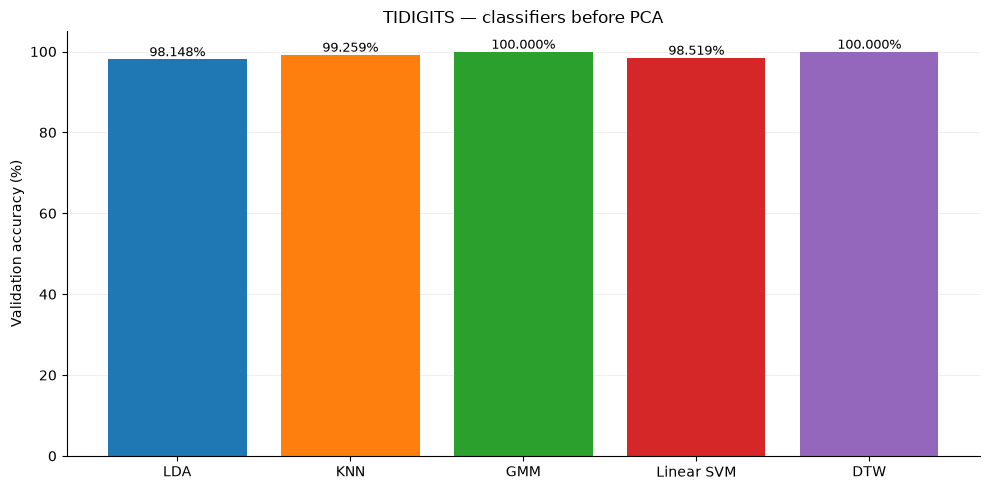

In [30]:
validation_results = [
    {
        "Classifier": "LDA",
        "Representation": "5-segment means",
        "Setting": "Shared covariance",
        "Validation accuracy (%)": 100 * lda_val_accuracy
    },
    {
        "Classifier": "KNN",
        "Representation": "5-segment means",
        "Setting": f"k={best_k}",
        "Validation accuracy (%)": 100 * best_knn_val_accuracy
    },
    {
        "Classifier": "GMM",
        "Representation": "Frame distributions",
        "Setting": (
            f"Diagonal, {best_components} components per digit"
        ),
        "Validation accuracy (%)": 100 * best_gmm_val_accuracy
    },
    {
        "Classifier": "Linear SVM",
        "Representation": "5-segment means",
        "Setting": f"One-versus-rest, C={best_C}",
        "Validation accuracy (%)": 100 * best_svm_val_accuracy
    },
    {
        "Classifier": "DTW",
        "Representation": "Full sequences",
        "Setting": (
            f"{best_template_count} templates per digit"
        ),
        "Validation accuracy (%)": 100 * best_dtw_val_accuracy
    }
]

validation_comparison = pd.DataFrame(
    validation_results
)

classifier_names = [
    "LDA", "KNN", "GMM", "Linear SVM", "DTW"
]

print("Before PCA — validation comparison:")
print(
    validation_comparison.round(3).to_string(index=False)
)

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(
    validation_comparison["Classifier"],
    validation_comparison["Validation accuracy (%)"],
    color=[
        "tab:blue",
        "tab:orange",
        "tab:green",
        "tab:red",
        "tab:purple"
    ]
)

for bar, accuracy in zip(
    bars,
    validation_comparison["Validation accuracy (%)"]
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        accuracy + 0.7,
        f"{accuracy:.3f}%",
        ha="center",
        fontsize=9
    )

ax.set_ylim(0, 105)
ax.set_ylabel("Validation accuracy (%)")
ax.set_title("TIDIGITS — classifiers before PCA")
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

In [31]:
#PCA
class ManualPCA:
    def fit(self, X):
        X = np.asarray(X, dtype=float)

        self.mean_ = X.mean(axis=0)
        centered = X - self.mean_

        covariance = (
            centered.T @ centered
        ) / (len(X) - 1)

        eigenvalues, eigenvectors = np.linalg.eigh(
            covariance
        )

        # Sort components by decreasing explained variance.
        order = np.argsort(eigenvalues)[::-1]

        self.eigenvalues_ = np.maximum(
            eigenvalues[order],
            0.0
        )

        self.components_ = eigenvectors[:, order]

        total_variance = self.eigenvalues_.sum()

        if total_variance <= 0:
            raise ValueError(
                "PCA requires nonzero training variance."
            )

        self.explained_variance_ratio_ = (
            self.eigenvalues_ / total_variance
        )

        self.cumulative_variance_ = np.cumsum(
            self.explained_variance_ratio_
        )

        return self

    def transform(self, X, n_components):
        X = np.asarray(X, dtype=float)

        if X.shape[1] != len(self.mean_):
            raise ValueError(
                "Input feature count differs from PCA training."
            )

        if not 1 <= n_components <= self.components_.shape[1]:
            raise ValueError(
                "Invalid number of PCA components."
            )

        return (
            X - self.mean_
        ) @ self.components_[:, :n_components]


frame_pca_model = ManualPCA()

frame_pca_model.fit(
    np.vstack(train_sequences_scaled)
)

K_values = [1, 2, 4, 8, 12, 20, 30, 39]

print("Frame-level PCA fitted using training data only.")
print("Original features per frame:", n_features)
print("PCA dimensions to evaluate:", K_values)


Frame-level PCA fitted using training data only.
Original features per frame: 39
PCA dimensions to evaluate: [1, 2, 4, 8, 12, 20, 30, 39]


 Principal component  Explained variance (%)  Cumulative variance (%)
                   1                  10.104                   10.104
                   2                   7.735                   17.839
                   3                   6.010                   23.849
                   4                   5.037                   28.886
                   5                   4.748                   33.635
                   6                   4.149                   37.784
                   7                   4.015                   41.799
                   8                   3.732                   45.531
                   9                   3.499                   49.030
                  10                   3.378                   52.408
                  11                   3.199                   55.607
                  12                   3.081                   58.688
                  13                   2.836                   61.524
                  14

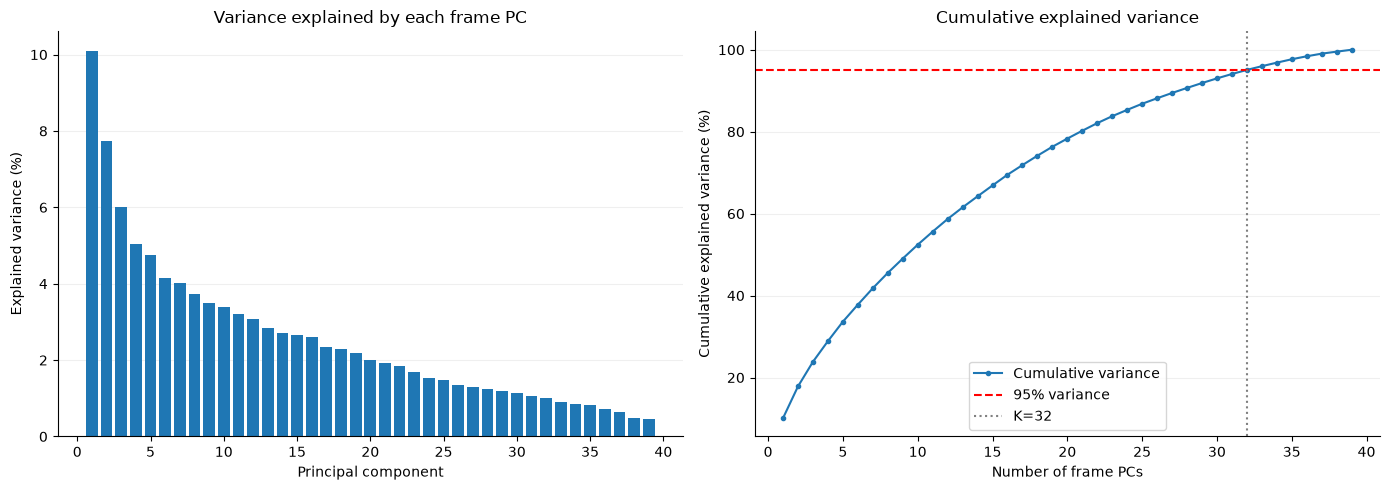

In [32]:
component_numbers = np.arange(1, n_features + 1)

pca_variance_table = pd.DataFrame({
    "Principal component": component_numbers,
    "Explained variance (%)": (
        100 * frame_pca_model.explained_variance_ratio_
    ),
    "Cumulative variance (%)": (
        100 * frame_pca_model.cumulative_variance_
    )
})

print(
    pca_variance_table.round(3).to_string(index=False)
)

K_95 = int(
    np.flatnonzero(
        frame_pca_model.cumulative_variance_
        >= 0.95 - 1e-12
    )[0] + 1
)

print(
    "\nComponents needed for at least 95% "
    f"training-frame variance: {K_95}"
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(
    component_numbers,
    100 * frame_pca_model.explained_variance_ratio_,
    color="tab:blue"
)

axes[0].set_title("Variance explained by each frame PC")
axes[0].set_xlabel("Principal component")
axes[0].set_ylabel("Explained variance (%)")

axes[1].plot(
    component_numbers,
    100 * frame_pca_model.cumulative_variance_,
    marker=".",
    label="Cumulative variance"
)

axes[1].axhline(
    95,
    color="red",
    linestyle="--",
    label="95% variance"
)

axes[1].axvline(
    K_95,
    color="gray",
    linestyle=":",
    label=f"K={K_95}"
)

axes[1].set_title("Cumulative explained variance")
axes[1].set_xlabel("Number of frame PCs")
axes[1].set_ylabel("Cumulative explained variance (%)")
axes[1].legend()

for ax in axes:
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

In [33]:
def project_sequences(sequence_list, pca, K):
    return [
        np.ascontiguousarray(
            pca.transform(sequence, K),
            dtype=np.float64
        )
        for sequence in sequence_list
    ]


def prepare_temporal_features(
    training_sequences,
    validation_sequences,
    segments
):
    training_features = temporal_pool_sequences(
        training_sequences,
        segments
    )

    validation_features = temporal_pool_sequences(
        validation_sequences,
        segments
    )

    # Estimate recording-level scaling on training data only.
    mean = training_features.mean(axis=0)
    std = training_features.std(axis=0)

    safe_std = np.where(
        std == 0,
        1.0,
        std
    )

    return (
        (training_features - mean) / safe_std,
        (validation_features - mean) / safe_std,
        mean,
        safe_std
    )


projection_rows = []

for K in K_values:
    projection_rows.append({
        "Frame PCA dimensions": K,
        "Temporal features per recording": n_segments * K,
        "Retained training variance (%)": (
            100 * frame_pca_model.cumulative_variance_[K - 1]
        )
    })

print(
    pd.DataFrame(projection_rows)
    .round(3)
    .to_string(index=False)
)

 Frame PCA dimensions  Temporal features per recording  Retained training variance (%)
                    1                                5                          10.104
                    2                               10                          17.839
                    4                               20                          28.886
                    8                               40                          45.531
                   12                               60                          58.688
                   20                              100                          78.314
                   30                              150                          93.006
                   39                              195                         100.000


In [34]:
pca_results = []
pca_selected_models = {}
pca_val_predictions = {}

for K in K_values:
    print(
        f"\nProcessing frame PCA K={K}...",
        flush=True
    )

    # Project each complete recording using training-fitted PCA.
    train_projected = project_sequences(
        train_sequences_scaled,
        frame_pca_model,
        K
    )

    val_projected = project_sequences(
        val_sequences_scaled,
        frame_pca_model,
        K
    )

    (
        train_temporal,
        val_temporal,
        temporal_mean,
        temporal_std
    ) = prepare_temporal_features(
        train_projected,
        val_projected,
        n_segments
    )

    # --------------------------------------------------
    # 1. LDA: temporal features
    # --------------------------------------------------
    print("  Fitting LDA...", flush=True)

    lda = ManualLDA(regularization=1e-4)
    lda.fit(train_temporal, y_train)

    lda_predictions = lda.predict(
        val_temporal
    )

    # --------------------------------------------------
    # 2. KNN: temporal features, fixed selected k
    # --------------------------------------------------
    print("  Evaluating KNN...", flush=True)

    knn = ManualKNN(batch_size=128)
    knn.fit(train_temporal, y_train)

    knn_predictions = knn.predict_for_k_values(
        val_temporal,
        [best_k]
    )[best_k]

    # --------------------------------------------------
    # 3. GMM: projected frame distributions
    # --------------------------------------------------
    print("  Fitting GMM...", flush=True)

    gmm = SpeechGMMClassifier(
        n_components=best_components,
        max_iter=200,
        tol=1e-4,
        variance_floor=1e-4
    )

    gmm.fit(
        train_projected,
        y_train
    )

    if not gmm.converged_:
        unconverged_digits = [
            int(digit)
            for digit, model in zip(
                gmm.classes_,
                gmm.models_
            )
            if not model.converged_
        ]

        raise RuntimeError(
            f"GMM did not converge for K={K}, "
            f"digits {unconverged_digits}. "
            "Inspect this fit before continuing."
        )

    gmm_predictions = gmm.predict(
        val_projected
    )

    # --------------------------------------------------
    # 4. Linear SVM: temporal features, fixed selected C
    # --------------------------------------------------
    print("  Fitting linear SVM...", flush=True)

    svm = ManualLinearSVM(
        C=best_C,
        max_iter=3000
    )

    svm.fit(
        train_temporal,
        y_train
    )

    if not svm.converged_:
        for digit, model in zip(
            svm.classes_,
            svm.models_
        ):
            if not model.converged_:
                print(
                    f"  Digit {digit}: "
                    f"{model.optimization_result_.message}"
                )

        raise RuntimeError(
            f"SVM did not fully converge for K={K}."
        )

    svm_predictions = svm.predict(
        val_temporal
    )

    # --------------------------------------------------
    # 5. DTW: projected complete sequences
    # --------------------------------------------------
    print("  Evaluating DTW...", flush=True)

    dtw = ManualDTWClassifier(
        templates_per_class=best_template_count
    )

    dtw.fit(
        train_projected,
        y_train
    )

    dtw_predictions = dtw.predict(
        val_projected,
        verbose=True
    )

    predictions = {
        "LDA": lda_predictions,
        "KNN": knn_predictions,
        "GMM": gmm_predictions,
        "Linear SVM": svm_predictions,
        "DTW": dtw_predictions
    }

    pca_val_predictions[K] = predictions

    # Store models and training-based scaling for testing later.
    pca_selected_models[K] = {
        "LDA": lda,
        "KNN": knn,
        "KNN neighbours": best_k,
        "GMM": gmm,
        "GMM components": best_components,
        "Linear SVM": svm,
        "SVM C": best_C,
        "DTW": dtw,
        "DTW templates per digit": best_template_count,
        "Temporal mean": temporal_mean,
        "Temporal std": temporal_std
    }

    row = {
        "K": K,
        "Temporal features": n_segments * K,
        "Retained variance (%)": (
            100 * frame_pca_model.cumulative_variance_[K - 1]
        )
    }

    for classifier in classifier_names:
        row[classifier] = (
            100 * accuracy_score_manual(
                y_val,
                predictions[classifier]
            )
        )

    pca_results.append(row)

    print(
        "  Completed: "
        + ", ".join(
            f"{name}={row[name]:.3f}%"
            for name in classifier_names
        ),
        flush=True
    )

pca_results_table = pd.DataFrame(
    pca_results
)

print("\nPCA validation accuracies (%):")
print(
    pca_results_table.round(3).to_string(index=False)
)


Processing frame PCA K=1...
  Fitting LDA...
  Evaluating KNN...
  Fitting GMM...
  Fitting linear SVM...
  Evaluating DTW...
  Processed 50/270 recordings
  Processed 100/270 recordings
  Processed 150/270 recordings
  Processed 200/270 recordings
  Processed 250/270 recordings
  Completed: LDA=67.778%, KNN=64.815%, GMM=70.370%, Linear SVM=68.148%, DTW=82.222%

Processing frame PCA K=2...
  Fitting LDA...
  Evaluating KNN...
  Fitting GMM...
  Fitting linear SVM...
  Evaluating DTW...
  Processed 50/270 recordings
  Processed 100/270 recordings
  Processed 150/270 recordings
  Processed 200/270 recordings
  Processed 250/270 recordings
  Completed: LDA=80.000%, KNN=86.667%, GMM=82.222%, Linear SVM=80.370%, DTW=94.444%

Processing frame PCA K=4...
  Fitting LDA...
  Evaluating KNN...
  Fitting GMM...
  Fitting linear SVM...
  Evaluating DTW...
  Processed 50/270 recordings
  Processed 100/270 recordings
  Processed 150/270 recordings
  Processed 200/270 recordings
  Processed 250/270 

Validation accuracy comparison (%):
            Representation    LDA     KNN     GMM  Linear SVM     DTW
Original 39 frame features 98.148  99.259 100.000      98.519 100.000
             Frame PCA K=1 67.778  64.815  70.370      68.148  82.222
             Frame PCA K=2 80.000  86.667  82.222      80.370  94.444
             Frame PCA K=4 94.444  96.296  96.296      94.074  99.259
             Frame PCA K=8 95.556  97.407  98.519      95.556  99.630
            Frame PCA K=12 95.556  98.519  99.630      96.296  99.259
            Frame PCA K=20 97.778  98.519  98.148      98.148  99.630
            Frame PCA K=30 98.519 100.000  98.889      99.259 100.000
            Frame PCA K=39 98.148 100.000  99.259      99.259 100.000


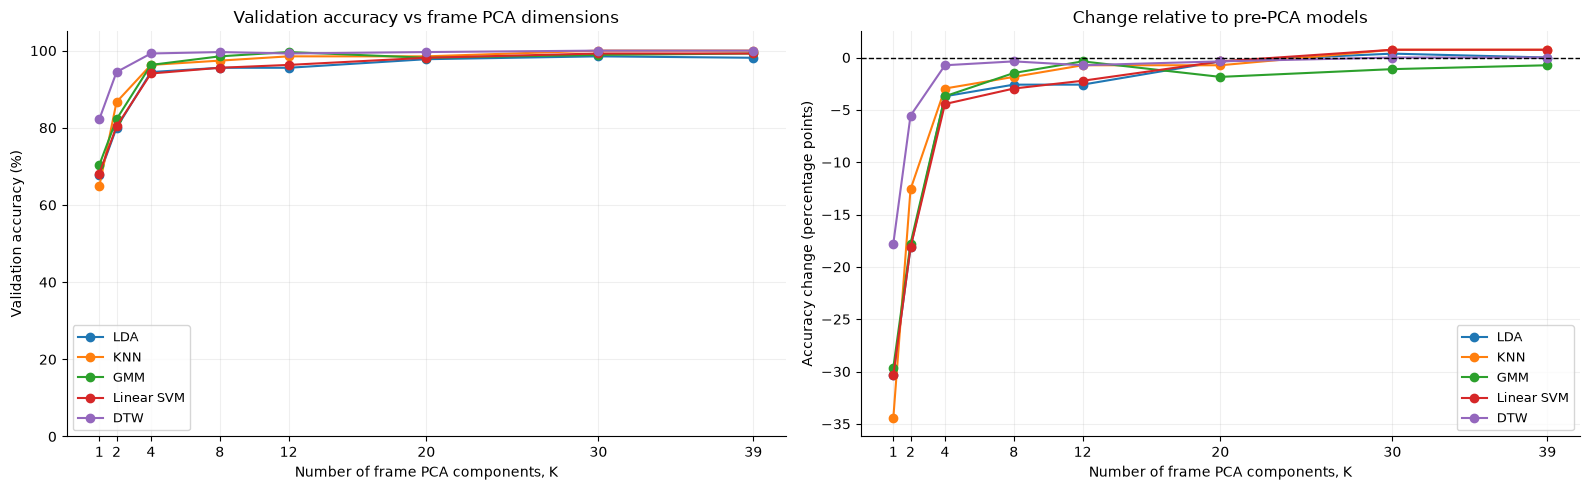

In [35]:
original_accuracies = dict(zip(
    validation_comparison["Classifier"],
    validation_comparison["Validation accuracy (%)"]
))

comparison_rows = [{
    "Representation": "Original 39 frame features",
    **{
        classifier: original_accuracies[classifier]
        for classifier in classifier_names
    }
}]

for _, row in pca_results_table.iterrows():
    comparison_rows.append({
        "Representation": f"Frame PCA K={int(row['K'])}",
        **{
            classifier: row[classifier]
            for classifier in classifier_names
        }
    })

original_vs_pca_table = pd.DataFrame(
    comparison_rows
)

print("Validation accuracy comparison (%):")
print(
    original_vs_pca_table.round(3).to_string(index=False)
)

colors = {
    "LDA": "tab:blue",
    "KNN": "tab:orange",
    "GMM": "tab:green",
    "Linear SVM": "tab:red",
    "DTW": "tab:purple"
}

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for classifier in classifier_names:
    axes[0].plot(
        pca_results_table["K"],
        pca_results_table[classifier],
        marker="o",
        color=colors[classifier],
        label=classifier
    )

    axes[1].plot(
        pca_results_table["K"],
        (
            pca_results_table[classifier]
            - original_accuracies[classifier]
        ),
        marker="o",
        color=colors[classifier],
        label=classifier
    )

axes[0].set_title("Validation accuracy vs frame PCA dimensions")
axes[0].set_ylabel("Validation accuracy (%)")
axes[0].set_ylim(0, 105)

axes[1].axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=1
)

axes[1].set_title("Change relative to pre-PCA models")
axes[1].set_ylabel("Accuracy change (percentage points)")

for ax in axes:
    ax.set_xlabel("Number of frame PCA components, K")
    ax.set_xticks(K_values)
    ax.legend(fontsize=9)
    ax.grid(alpha=0.2)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

In [36]:
# Select the best REDUCED K using validation accuracy only.
# Ties favour fewer PCA components.
reduced_validation_results = pca_results_table[
    pca_results_table["K"] < n_features
].copy()

selected_reduced_K = {}

for classifier in classifier_names:
    ranked = reduced_validation_results.sort_values(
        by=[classifier, "K"],
        ascending=[False, True]
    )

    selected_reduced_K[classifier] = int(
        ranked.iloc[0]["K"]
    )

print("Reduced PCA dimensions selected using validation:")
print(selected_reduced_K)

# --------------------------------------------------
# Test the original, pre-PCA models.
# --------------------------------------------------
print("\nEvaluating original models on test recordings...")

original_test_predictions = {
    "LDA": lda_model.predict(X_test_scaled),

    "KNN": knn_model.predict_for_k_values(
        X_test_scaled,
        [best_k]
    )[best_k],

    "GMM": best_gmm_model.predict(
        test_sequences_scaled
    ),

    "Linear SVM": best_svm_model.predict(
        X_test_scaled
    )
}

print("Evaluating original DTW...", flush=True)

original_test_predictions["DTW"] = best_dtw_model.predict(
    test_sequences_scaled,
    verbose=True
)

original_settings = {
    "LDA": "Shared covariance",
    "KNN": f"k={best_k}",
    "GMM": f"Diagonal, {best_components} components per digit",
    "Linear SVM": f"One-versus-rest, C={best_C}",
    "DTW": f"{best_template_count} templates per digit"
}

original_test_rows = []

for classifier in classifier_names:
    predictions = original_test_predictions[classifier]

    correct = int(np.sum(predictions == y_test))

    original_test_rows.append({
        "Classifier": classifier,
        "Setting": original_settings[classifier],
        "Correct": correct,
        "Errors": len(y_test) - correct,
        "Test accuracy (%)": (
            100 * correct / len(y_test)
        )
    })

original_test_table = pd.DataFrame(
    original_test_rows
)

original_test_accuracies = dict(zip(
    original_test_table["Classifier"],
    original_test_table["Test accuracy (%)"]
))

print("\nOriginal features — final test results:")
print(
    original_test_table.round(3).to_string(index=False)
)

Reduced PCA dimensions selected using validation:
{'LDA': 30, 'KNN': 30, 'GMM': 12, 'Linear SVM': 30, 'DTW': 30}

Evaluating original models on test recordings...
Evaluating original DTW...
  Processed 50/270 recordings
  Processed 100/270 recordings
  Processed 150/270 recordings
  Processed 200/270 recordings
  Processed 250/270 recordings

Original features — final test results:
Classifier                          Setting  Correct  Errors  Test accuracy (%)
       LDA                Shared covariance      266       4             98.519
       KNN                              k=3      265       5             98.148
       GMM Diagonal, 4 components per digit      270       0            100.000
Linear SVM           One-versus-rest, C=1.0      266       4             98.519
       DTW            5 templates per digit      269       1             99.630


In [37]:
pca_test_predictions = {}
pca_test_rows = []

for K in K_values:
    print(
        f"\nTesting frame PCA K={K}...",
        flush=True
    )

    selected = pca_selected_models[K]

    # Project test sequences without fitting PCA again.
    test_projected = project_sequences(
        test_sequences_scaled,
        frame_pca_model,
        K
    )

    # Create recording-level features for LDA, KNN, and SVM.
    test_temporal_raw = temporal_pool_sequences(
        test_projected,
        n_segments
    )

    # Apply the corresponding TRAINING scaling statistics.
    test_temporal = (
        test_temporal_raw - selected["Temporal mean"]
    ) / selected["Temporal std"]

    neighbours = selected["KNN neighbours"]

    predictions = {
        "LDA": selected["LDA"].predict(
            test_temporal
        ),

        "KNN": selected["KNN"].predict_for_k_values(
            test_temporal,
            [neighbours]
        )[neighbours],

        "GMM": selected["GMM"].predict(
            test_projected
        ),

        "Linear SVM": selected["Linear SVM"].predict(
            test_temporal
        )
    }

    print("  Evaluating DTW...", flush=True)

    predictions["DTW"] = selected["DTW"].predict(
        test_projected,
        verbose=True
    )

    pca_test_predictions[K] = predictions

    row = {
        "K": K,
        "Temporal features": n_segments * K,
        "Retained training variance (%)": (
            100 * frame_pca_model.cumulative_variance_[K - 1]
        )
    }

    for classifier in classifier_names:
        row[classifier] = (
            100 * accuracy_score_manual(
                y_test,
                predictions[classifier]
            )
        )

    pca_test_rows.append(row)

    print(
        "  Completed: "
        + ", ".join(
            f"{name}={row[name]:.3f}%"
            for name in classifier_names
        ),
        flush=True
    )

pca_test_table = pd.DataFrame(
    pca_test_rows
)

print("\nPCA test accuracies (%):")
print(
    pca_test_table.round(3).to_string(index=False)
)


Testing frame PCA K=1...


  Evaluating DTW...
  Processed 50/270 recordings
  Processed 100/270 recordings
  Processed 150/270 recordings
  Processed 200/270 recordings
  Processed 250/270 recordings
  Completed: LDA=62.963%, KNN=63.333%, GMM=58.889%, Linear SVM=63.333%, DTW=78.519%

Testing frame PCA K=2...
  Evaluating DTW...
  Processed 50/270 recordings
  Processed 100/270 recordings
  Processed 150/270 recordings
  Processed 200/270 recordings
  Processed 250/270 recordings
  Completed: LDA=78.519%, KNN=85.185%, GMM=83.704%, Linear SVM=80.370%, DTW=91.481%

Testing frame PCA K=4...
  Evaluating DTW...
  Processed 50/270 recordings
  Processed 100/270 recordings
  Processed 150/270 recordings
  Processed 200/270 recordings
  Processed 250/270 recordings
  Completed: LDA=94.074%, KNN=96.667%, GMM=96.667%, Linear SVM=93.704%, DTW=98.148%

Testing frame PCA K=8...
  Evaluating DTW...
  Processed 50/270 recordings
  Processed 100/270 recordings
  Processed 150/270 recordings
  Processed 200/270 recordings
  Pro

In [38]:
# --------------------------------------------------
# A. All original and PCA test accuracies.
# --------------------------------------------------
final_rows = [{
    "Representation": "Original 39 frame features",
    **{
        classifier: original_test_accuracies[classifier]
        for classifier in classifier_names
    }
}]

for _, row in pca_test_table.iterrows():
    final_rows.append({
        "Representation": f"Frame PCA K={int(row['K'])}",
        **{
            classifier: row[classifier]
            for classifier in classifier_names
        }
    })

final_test_comparison = pd.DataFrame(
    final_rows
)

print("Final comparison — TEST accuracy (%):")
print(
    final_test_comparison.round(3).to_string(index=False)
)

# --------------------------------------------------
# B. Validation-selected reduced models.
# --------------------------------------------------
reduced_summary_rows = []

for classifier in classifier_names:
    K = selected_reduced_K[classifier]

    predictions = pca_test_predictions[K][classifier]

    reduced_accuracy = (
        100 * accuracy_score_manual(
            y_test,
            predictions
        )
    )

    reduced_summary_rows.append({
        "Classifier": classifier,
        "Reduced K chosen on validation": K,
        "Frame dimensions removed (%)": (
            100 * (n_features - K) / n_features
        ),
        "Retained training variance (%)": (
            100 * frame_pca_model.cumulative_variance_[K - 1]
        ),
        "Original test accuracy (%)": (
            original_test_accuracies[classifier]
        ),
        "Reduced PCA test accuracy (%)": reduced_accuracy,
        "Change (percentage points)": (
            reduced_accuracy
            - original_test_accuracies[classifier]
        )
    })

reduced_pca_summary = pd.DataFrame(
    reduced_summary_rows
)

print("\nValidation-selected reduced PCA models:")
print(
    reduced_pca_summary.round(3).to_string(index=False)
)

# --------------------------------------------------
# C. Original models: validation versus test.
# --------------------------------------------------
validation_lookup = dict(zip(
    validation_comparison["Classifier"],
    validation_comparison["Validation accuracy (%)"]
))

validation_test_comparison = pd.DataFrame([
    {
        "Classifier": classifier,
        "Validation accuracy (%)": validation_lookup[classifier],
        "Test accuracy (%)": original_test_accuracies[classifier],
        "Test minus validation (percentage points)": (
            original_test_accuracies[classifier]
            - validation_lookup[classifier]
        )
    }
    for classifier in classifier_names
])

print("\nOriginal models — validation versus test:")
print(
    validation_test_comparison.round(3).to_string(index=False)
)

Final comparison — TEST accuracy (%):
            Representation    LDA    KNN     GMM  Linear SVM     DTW
Original 39 frame features 98.519 98.148 100.000      98.519  99.630
             Frame PCA K=1 62.963 63.333  58.889      63.333  78.519
             Frame PCA K=2 78.519 85.185  83.704      80.370  91.481
             Frame PCA K=4 94.074 96.667  96.667      93.704  98.148
             Frame PCA K=8 95.926 97.778  99.259      96.296  99.630
            Frame PCA K=12 98.148 97.407  98.889      97.778  99.630
            Frame PCA K=20 98.519 97.407  98.519      98.519  99.630
            Frame PCA K=30 98.519 98.148  99.630      98.148 100.000
            Frame PCA K=39 98.519 98.148 100.000      98.519  99.630

Validation-selected reduced PCA models:
Classifier  Reduced K chosen on validation  Frame dimensions removed (%)  Retained training variance (%)  Original test accuracy (%)  Reduced PCA test accuracy (%)  Change (percentage points)
       LDA                             

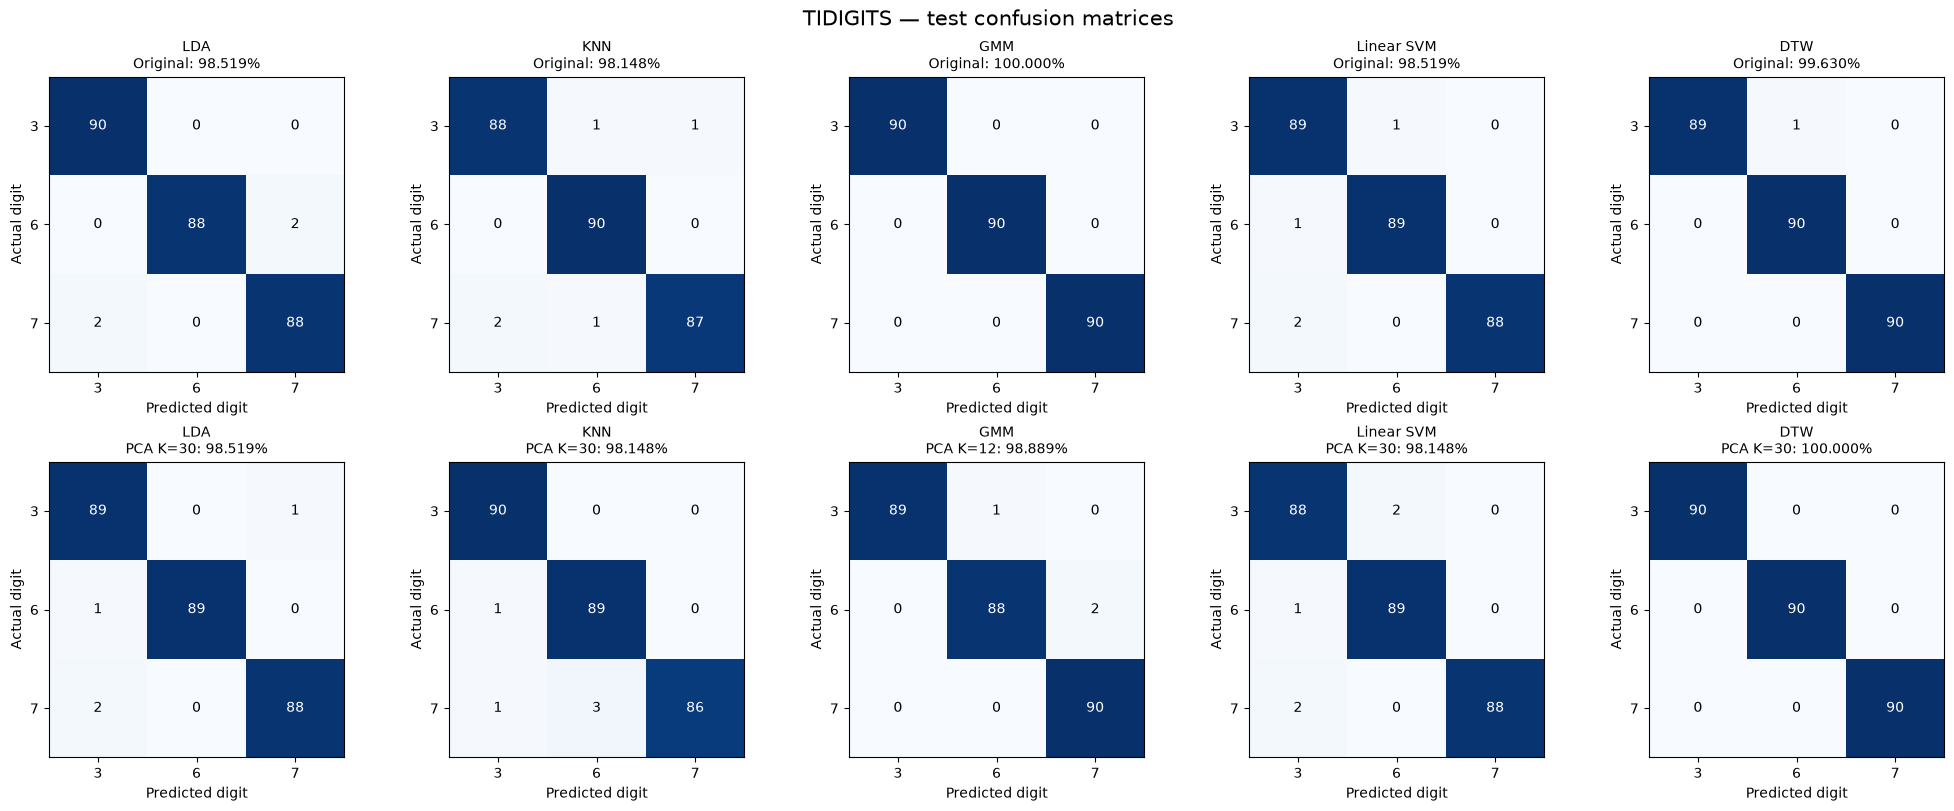

In [39]:
def plot_confusion_matrix_manual(
    ax,
    y_true,
    y_pred,
    title
):
    matrix = confusion_matrix_manual(
        y_true,
        y_pred
    )

    color_max = max(
        1,
        int(matrix.sum(axis=1).max())
    )

    ax.imshow(
        matrix,
        cmap="Blues",
        vmin=0,
        vmax=color_max
    )

    for row in range(len(class_labels)):
        for column in range(len(class_labels)):
            value = matrix[row, column]

            ax.text(
                column,
                row,
                str(value),
                ha="center",
                va="center",
                color=(
                    "white"
                    if value > color_max / 2
                    else "black"
                ),
                fontsize=10
            )

    positions = np.arange(len(class_labels))

    ax.set_xticks(positions)
    ax.set_yticks(positions)
    ax.set_xticklabels(class_labels)
    ax.set_yticklabels(class_labels)

    ax.set_xlabel("Predicted digit")
    ax.set_ylabel("Actual digit")
    ax.set_title(title, fontsize=10)


fig, axes = plt.subplots(
    2,
    len(classifier_names),
    figsize=(20, 8),
    constrained_layout=True
)

for column, classifier in enumerate(classifier_names):
    # Original model.
    original_predictions = original_test_predictions[
        classifier
    ]

    original_accuracy = original_test_accuracies[
        classifier
    ]

    plot_confusion_matrix_manual(
        axes[0, column],
        y_test,
        original_predictions,
        f"{classifier}\nOriginal: {original_accuracy:.3f}%"
    )

    # Validation-selected reduced model.
    K = selected_reduced_K[classifier]

    reduced_predictions = pca_test_predictions[K][
        classifier
    ]

    reduced_accuracy = (
        100 * accuracy_score_manual(
            y_test,
            reduced_predictions
        )
    )

    plot_confusion_matrix_manual(
        axes[1, column],
        y_test,
        reduced_predictions,
        f"{classifier}\nPCA K={K}: {reduced_accuracy:.3f}%"
    )

fig.suptitle(
    "TIDIGITS — test confusion matrices",
    fontsize=15
)

plt.show()

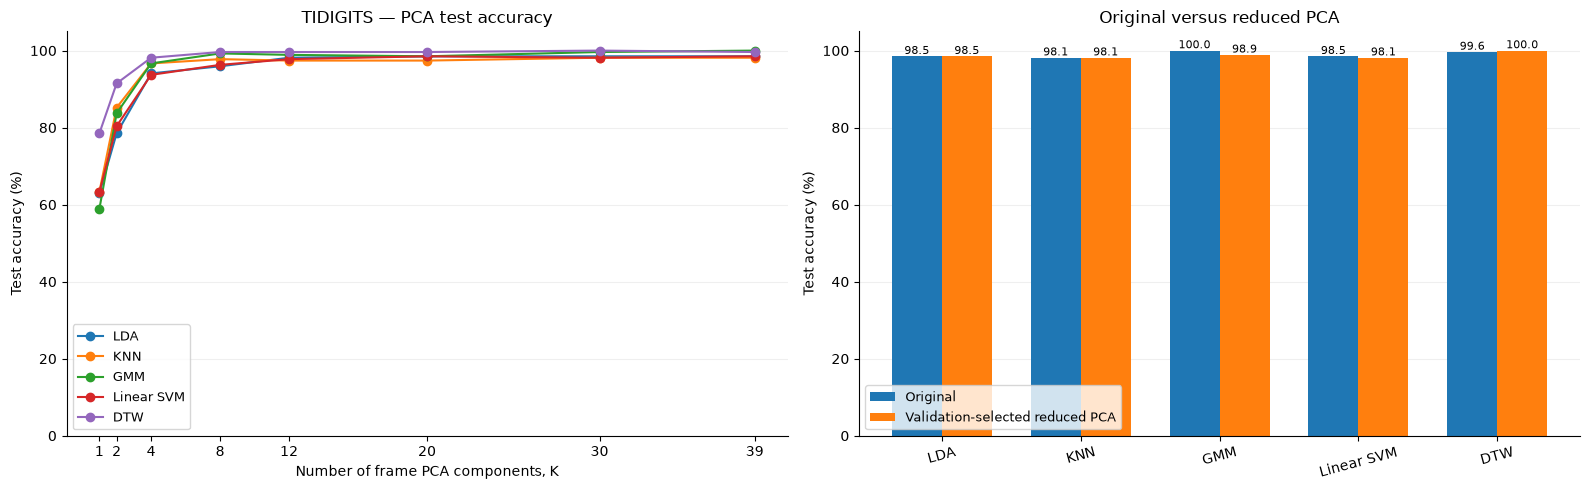

FINAL TEST OBSERVATIONS
-----------------------------------------------------------------

LDA: original = 98.519%, reduced PCA K=30 = 98.519%.
  Accuracy change: +0.000 percentage points.

KNN: original = 98.148%, reduced PCA K=30 = 98.148%.
  Accuracy change: +0.000 percentage points.

GMM: original = 100.000%, reduced PCA K=12 = 98.889%.
  Accuracy change: -1.111 percentage points.

Linear SVM: original = 98.519%, reduced PCA K=30 = 98.148%.
  Accuracy change: -0.370 percentage points.

DTW: original = 99.630%, reduced PCA K=30 = 100.000%.
  Accuracy change: +0.370 percentage points.

Evaluation notes:
• PCA and scaling were fitted using training data only.
• Classifier settings and reduced K were selected using validation data.
• Test results were used for final reporting, not tuning.
• LDA, KNN, and SVM used temporal segment means.
• GMM used frame distributions; DTW used complete sequences.
• DTW used a selected subset of training templates.
• The split is recording-level; speake

In [40]:
colors = {
    "LDA": "tab:blue",
    "KNN": "tab:orange",
    "GMM": "tab:green",
    "Linear SVM": "tab:red",
    "DTW": "tab:purple"
}

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# --------------------------------------------------
# A. Test accuracy across PCA dimensions.
# --------------------------------------------------
for classifier in classifier_names:
    axes[0].plot(
        pca_test_table["K"],
        pca_test_table[classifier],
        marker="o",
        color=colors[classifier],
        label=classifier
    )

axes[0].set_xlabel("Number of frame PCA components, K")
axes[0].set_ylabel("Test accuracy (%)")
axes[0].set_title("TIDIGITS — PCA test accuracy")
axes[0].set_xticks(K_values)
axes[0].set_ylim(0, 105)
axes[0].legend(fontsize=9)

# --------------------------------------------------
# B. Original versus validation-selected reduced models.
# --------------------------------------------------
positions = np.arange(len(classifier_names))
width = 0.36

original_values = [
    original_test_accuracies[classifier]
    for classifier in classifier_names
]

reduced_values = [
    100 * accuracy_score_manual(
        y_test,
        pca_test_predictions[
            selected_reduced_K[classifier]
        ][classifier]
    )
    for classifier in classifier_names
]

original_bars = axes[1].bar(
    positions - width / 2,
    original_values,
    width,
    label="Original",
    color="tab:blue"
)

reduced_bars = axes[1].bar(
    positions + width / 2,
    reduced_values,
    width,
    label="Validation-selected reduced PCA",
    color="tab:orange"
)

for bars in [original_bars, reduced_bars]:
    for bar in bars:
        axes[1].text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.6,
            f"{bar.get_height():.1f}",
            ha="center",
            fontsize=8
        )

axes[1].set_xticks(positions)
axes[1].set_xticklabels(
    classifier_names,
    rotation=15
)

axes[1].set_ylabel("Test accuracy (%)")
axes[1].set_ylim(0, 105)
axes[1].set_title("Original versus reduced PCA")
axes[1].legend(fontsize=9)

for ax in axes:
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

# --------------------------------------------------
# C. Final numerical observations.
# --------------------------------------------------
print("FINAL TEST OBSERVATIONS")
print("-" * 65)

for _, row in reduced_pca_summary.iterrows():
    print(
        f"\n{row['Classifier']}: "
        f"original = {row['Original test accuracy (%)']:.3f}%, "
        f"reduced PCA K="
        f"{int(row['Reduced K chosen on validation'])} "
        f"= {row['Reduced PCA test accuracy (%)']:.3f}%."
    )

    print(
        "  Accuracy change: "
        f"{row['Change (percentage points)']:+.3f} "
        "percentage points."
    )

print(
    "\nEvaluation notes:\n"
    "• PCA and scaling were fitted using training data only.\n"
    "• Classifier settings and reduced K were selected using "
    "validation data.\n"
    "• Test results were used for final reporting, not tuning.\n"
    "• LDA, KNN, and SVM used temporal segment means.\n"
    "• GMM used frame distributions; DTW used complete sequences.\n"
    "• DTW used a selected subset of training templates.\n"
    "• The split is recording-level; speaker independence "
    "could not be verified."
)

In [41]:
results = pca_results_table.melt(
    id_vars="K",
    value_vars=["LDA", "KNN", "GMM", "Linear SVM"],
    var_name="Classifier",
    value_name="Accuracy"
)

best_pca = results.sort_values(
    ["Accuracy", "K", "Classifier"],
    ascending=[False, True, True]
).iloc[0]

print("BEST PCA MODEL")
print("-------------------------")
print("Classifier:", best_pca["Classifier"])
print("PCA Components:", int(best_pca["K"]))
print(f"Validation Accuracy: {best_pca['Accuracy']:.3f}%")

BEST PCA MODEL
-------------------------
Classifier: KNN
PCA Components: 30
Validation Accuracy: 100.000%


In [42]:
selected_K = int(best_pca["K"])
selected_classifier = best_pca["Classifier"]

selected_test_accuracy = pca_test_table.set_index("K").loc[
    selected_K, selected_classifier
]

print("FINAL TEST RESULTS")
print("-------------------------")
print("Best Classifier:", selected_classifier)
print("PCA Components:", selected_K)
print(f"Test Accuracy: {selected_test_accuracy:.3f}%")

FINAL TEST RESULTS
-------------------------
Best Classifier: KNN
PCA Components: 30
Test Accuracy: 98.148%


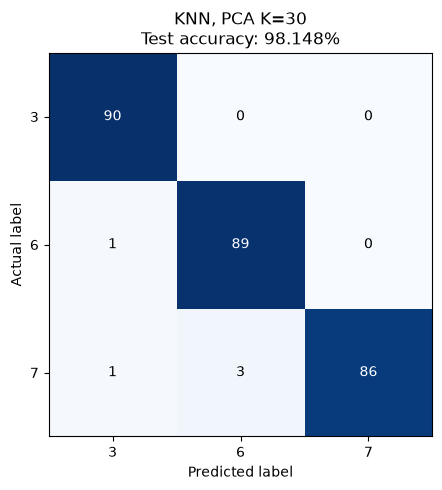

In [43]:
predictions = pca_test_predictions[selected_K][selected_classifier]

matrix = confusion_matrix_manual(y_test, predictions)
labels = np.unique(np.concatenate([y_test, predictions]))

plt.figure(figsize=(6, 5))
plt.imshow(matrix, cmap="Blues")

for row in range(len(labels)):
    for column in range(len(labels)):
        plt.text(
            column, row, matrix[row, column],
            ha="center",
            va="center",
            color="white" if matrix[row, column] > matrix.max() / 2
            else "black"
        )

plt.xticks(range(len(labels)), labels)
plt.yticks(range(len(labels)), labels)
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.title(
    f"{selected_classifier}, PCA K={selected_K}\n"
    f"Test accuracy: {selected_test_accuracy:.3f}%"
)
plt.tight_layout()
plt.show()